# Transformer Architecture

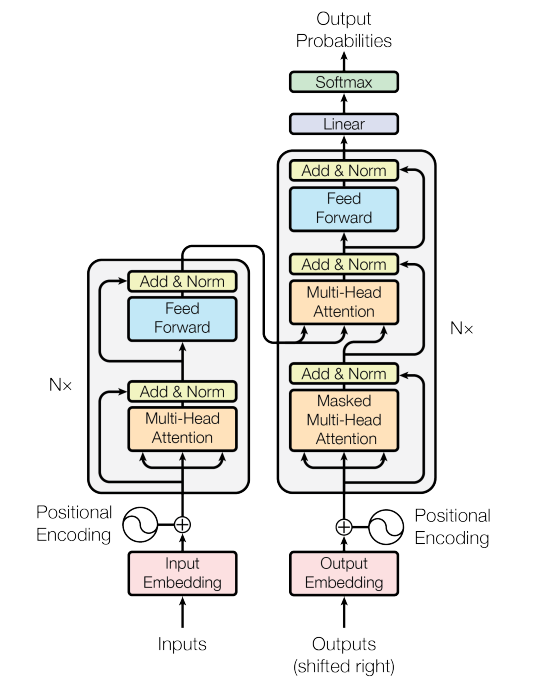

In [2]:
from pathlib import Path
import sys

path = Path("..").resolve()

if str(path) not in sys.path:
    sys.path.append(str(path))

In [3]:
import torch
import torch.nn as nn
from src.model import Embedding, PositionalEncoding, Encoder, Decoder
from src.functional import softmax


In [ ]:
class Transformer(nn.Module):
    def __init__(
        self,
        src_vocab_size,
        tgt_vocab_size,
        max_len,
        d_ff: int = 2048,
        d_model: int = 512,
        num_heads: int = 8,
        num_encoder_layers: int = 6,
        num_decoder_layers: int = 6,
        device: torch.device | None = None,
        dropout: float = 0.1
    ):
    
        super().__init__()
        self.max_len = max_len

        self.src_embedding = Embedding(
            num_embeddings=src_vocab_size,
            embedding_dim=d_model,
            device=device
        )

        self.tgt_embedding = Embedding(
            num_embeddings=tgt_vocab_size,
            embedding_dim=d_model,
            device=device
        )

        self.pos_emb = PositionalEncoding(
            max_len=self.max_len,
            d_model=d_model,
            device=device
        )

        self.encoder = Encoder(
            d_model=d_model,
            d_ff=d_ff,
            num_heads=num_heads,
            num_layers=num_encoder_layers,
            device=device,
            dropout=dropout
        )

        self.decoder = Decoder(
            d_model=d_model,
            d_ff=d_ff,
            num_heads=num_heads,
            num_layers=num_decoder_layers,
            device=device,
            dropout=dropout      
        )

        self.output = nn.Linear(
            in_features=d_model,
            out_features=tgt_vocab_size,
            device=device
        )

    def forward(
        self,
        src: torch.Tensor,
        tgt: torch.Tensor,
        pad_id: int,
        *,
        output_prob=False
    ):

        #src padding mask
        src_pad_mask = (src != pad_id).unsqueeze(1).unsqueeze(2) #shape para Attention

        #tgt padding mask
        tgt_pad_mask = (tgt != pad_id).unsqueeze(1).unsqueeze(2) #shape para Attention       
        
        #encoder input
        src_pos_embed = self.pos_emb(self.src_embedding(src))
        memory = self.encoder(
            src_pos_embed,
            attn_mask=src_pad_mask
        )

        #decoder input
        tgt_pos_embed = self.pos_emb(self.tgt_embedding(tgt))

        output = self.decoder(
            x=tgt_pos_embed,
            memory=memory,
            src_mask=src_pad_mask,
            tgt_padding=tgt_pad_mask
        )

        #nesse ponto armazena os logits
        output = self.output(
            output
        )

        if output_prob:
            output = softmax(
                output,
                dim=-1
            )

        return output

        
